# Supplement Dose Analysis

How does tooth length differ by supplement dose?

Data: [datasets/ToothGrowth](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/ToothGrowth.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Guinea-pig experiment; findings are not human medical advice.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Supplement Dose Analysis',
 'executed_utc': '2026-11-21T10:14:11.808680+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/ToothGrowth.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/ToothGrowth.html',
 'sha256': 'b35e084a98731429169eb9b216c9b904e8b9ea127707b741bb8fc146354c26fe',
 'raw_rows': 60,
 'analysis_rows': 60,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,60
1,len,float64,0,0.0,43
2,supp,object,0,0.0,2
3,dose,float64,0,0.0,3


## SQL and analysis
Complete-case descriptive comparison of len by dose; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "dose" AS segment, COUNT(*) AS rows_used, AVG("len") AS metric, MIN("len") AS minimum, MAX("len") AS maximum FROM observations GROUP BY "dose" ORDER BY "dose";

The largest observed mean len is 26.100 for 2.0. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,0.5,20,10.605,4.2,21.5
1,1.0,20,19.735,13.6,27.3
2,2.0,20,26.100,18.5,33.9


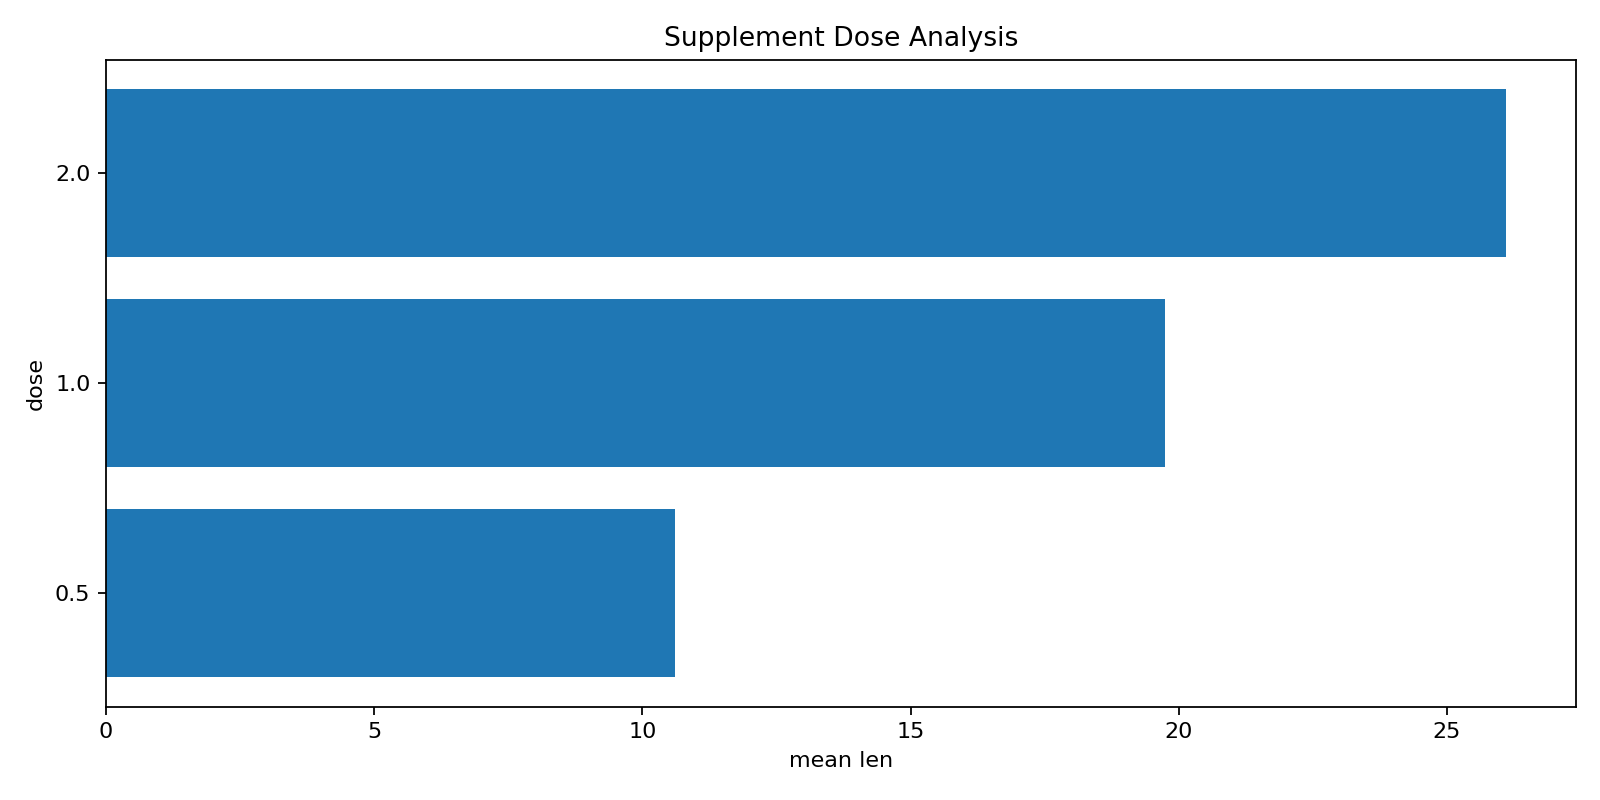

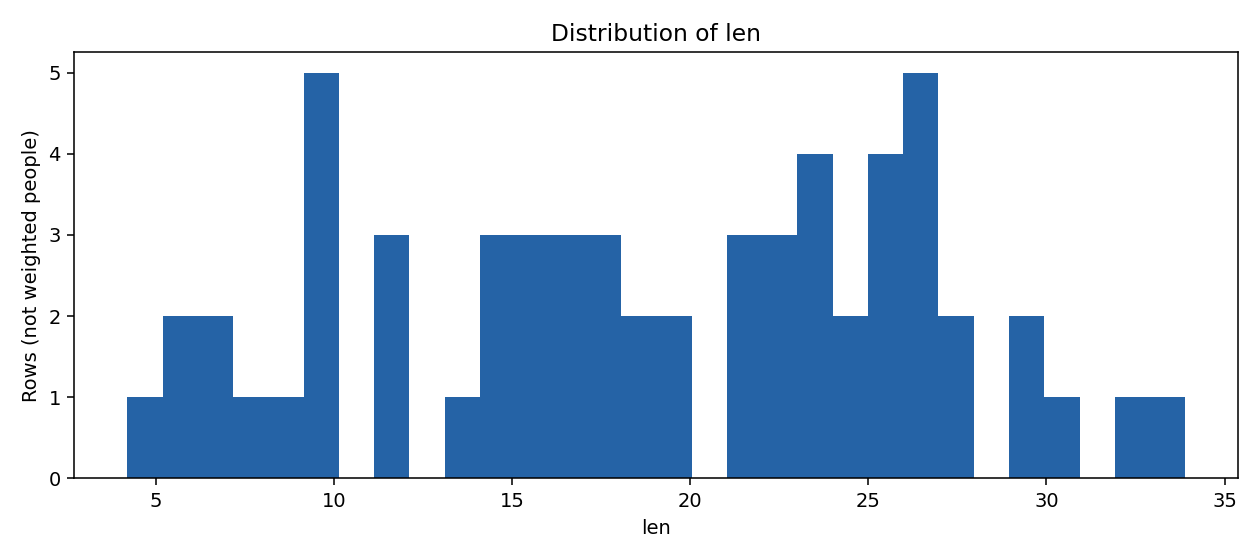

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Guinea-pig experiment; findings are not human medical advice.

**Next action:** Inspect supplement-specific dose patterns and experimental design.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.